# Cloud-Native Climate Analysis — European Cities
## Temperature Anomaly and Population Exposure using Overture Maps Divisions and ERA5

**Question:** which European cities (population ≥ 500,000) have the largest temperature
anomaly in 2021–2024 relative to the 1991–2020 WMO climatological baseline, and how many
people live in them?

**Data** (streamed from public cloud storage, no downloads):
- **Overture Maps** `divisions` theme (GeoParquet on S3, queried with **DuckDB**): city
  locations with a `population` attribute, plus country, province and city boundary polygons.
- **Planette's ERA5 Archive** (Zarr + Icechunk on S3, read with **XArray**): ERA5 2 m
  temperature, 1991–2024. The archive's `t2m_max` variable behaves like daily **mean**
  temperature (see the check in Section 5), so it is labelled `t2m` throughout.

**Temperature anomaly:**

```
anomaly = observed_t2m - climatological_normal
```

The climatological normal is the mean temperature for each calendar month over the WMO
standard reference period 1991–2020. Removing the seasonal cycle isolates the long-term
warming signal.

**Caveat:** ERA5's ~0.25° grid (~28 km) represents regional climate, not the urban surface.
The anomalies are the regional signal at each city's location and do not include the urban
heat island effect, which can add 1–3 °C in large built-up cities.


---
## 1. Setup

### Determine the runtime environment

This lets the same notebook run unmodified on Google Colab or on a local/conda
environment.

In [1]:
import os

if 'COLAB_RELEASE_TAG' in os.environ:
    environment = 'colab'
    if os.environ.get('VERTEX_PRODUCT') == 'COLAB_ENTERPRISE':
        environment = 'colab_enterprise'
else:
    environment = 'local'

print(f'Environment: {environment}')

Environment: colab


### Install packages

Colab needs these installed; local/conda environments are expected to have them already.

In [2]:
%%capture
if environment in ['colab', 'colab_enterprise']:
    !pip install duckdb geopandas shapely pyproj folium branca \
        matplotlib seaborn requests pandas numpy \
        xarray zarr icechunk dask


### Import libraries

Import everything up front for clarity.

In [3]:
import time

import dask
import duckdb
import folium
import geopandas as gpd
import icechunk as ic
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import xarray as xr
from folium.plugins import MarkerCluster

print(f'DuckDB version: {duckdb.__version__}')
print(f'XArray version: {xr.__version__}')
print(f'Dask version: {dask.__version__}')
print('All libraries loaded.')


DuckDB version: 1.3.2
XArray version: 2025.12.0
Dask version: 2026.8.0
All libraries loaded.


### Data and output folders

Mount Google Drive for persistent storage on Colab (local filesystem is wiped when
the runtime disconnects), otherwise use local `data`/`output` folders.

In [4]:
# Set to True to use Google Drive for data storage in Colab
use_google_drive = True

if environment == 'colab' and use_google_drive:
    from google.colab import drive
    drive.mount('/content/drive')
    drive_folder_root = 'MyDrive'
    drive_data_folder = 'python-remote-sensing-europe-climate'
    drive_folder_path = os.path.join('/content/drive', drive_folder_root, drive_data_folder)
    data_folder = drive_folder_path
    output_folder = drive_folder_path
else:
    data_folder = 'data'
    output_folder = 'output'

if not os.path.exists(data_folder):
    os.makedirs(data_folder)
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

print(f'Environment: {environment}')
print(f'Data folder: {data_folder}')
print(f'Output folder: {output_folder}')

Mounted at /content/drive
Environment: colab
Data folder: /content/drive/MyDrive/python-remote-sensing-europe-climate
Output folder: /content/drive/MyDrive/python-remote-sensing-europe-climate


### Run options, caches and timing

Switches for the performance features and the cache locations. The defaults give the fastest run:

- `USE_MONTHLY_STORE = True`: read Planette's monthly store, since the anomaly method only
  needs monthly means. It is checked against the daily store in Section 5; on any mismatch
  the daily store is used.
- `RECOMPUTE_GRIDS = False`: reuse the anomaly grids cached on disk
  (`era5_anomaly_grids.nc`) when their settings match this run.
- `REFRESH_OVERTURE = False`: reuse the cached Overture polygons
  (`overture_division_areas.parquet`) when they were queried for the same release, domain
  and candidate cities.

The `timed()` helper prints how long each heavy step takes; a summary is printed at the end.


In [5]:
import json
from contextlib import contextmanager

# --- Run options -------------------------------------------------------------------
# Read Planette's pre-computed monthly t2m_max store (about 31x less data than the daily
# store). Checked against the daily store in Section 5; the daily store is used on any mismatch.
USE_MONTHLY_STORE = True

# Reuse the anomaly grids cached on disk (Section 5). Set True to re-read ERA5 and
# recompute, e.g. after changing the method.
RECOMPUTE_GRIDS = False

# Reuse the cached Overture division_area polygons (Section 3). Set True to re-query S3.
REFRESH_OVERTURE = False

# Simplification tolerance (degrees) for country polygons in the choropleth and land mask.
# 0.02 deg is ~2 km -- invisible at Europe zoom.
SIMPLIFY_DEG = 0.02

GRIDS_CACHE_PATH = os.path.join(output_folder, 'era5_anomaly_grids.nc')
DIVISION_AREAS_CACHE_PATH = os.path.join(output_folder, 'overture_division_areas.parquet')
DIVISION_AREAS_META_PATH = os.path.join(output_folder, 'overture_division_areas.json')


def grid_cache_params():
    """Settings the cached grids must match to be reused (stored as netCDF attributes)."""
    return {
        'variable': VARIABLE, 'grid': GRID,
        'era5_bbox': json.dumps(ERA5_BBOX, sort_keys=True),
        'baseline': '1991-2020', 'recent': '2021-2024',
        'method': 'monthly means, monthly climatology, equal-month annual mean',
    }


def grids_cache_usable():
    """True if cached grids exist, match this run's settings, and RECOMPUTE_GRIDS is off."""
    if RECOMPUTE_GRIDS or not os.path.exists(GRIDS_CACHE_PATH):
        return False
    with xr.open_dataset(GRIDS_CACHE_PATH) as cached:
        return all(str(cached.attrs.get(k)) == str(v) for k, v in grid_cache_params().items())


# --- Timing ------------------------------------------------------------------------
timings = {}


@contextmanager
def timed(label):
    """Record and print the wall-clock time of the enclosed block."""
    t0 = time.perf_counter()
    try:
        yield
    finally:
        timings[label] = time.perf_counter() - t0
        print(f'[timing] {label}: {timings[label]:.1f}s')


print(f'USE_MONTHLY_STORE={USE_MONTHLY_STORE} | RECOMPUTE_GRIDS={RECOMPUTE_GRIDS} | '
      f'REFRESH_OVERTURE={REFRESH_OVERTURE}')
print(f'Grid cache:     {GRIDS_CACHE_PATH} (exists: {os.path.exists(GRIDS_CACHE_PATH)})')
print(f'Overture cache: {DIVISION_AREAS_CACHE_PATH} (exists: {os.path.exists(DIVISION_AREAS_CACHE_PATH)})')


USE_MONTHLY_STORE=True | RECOMPUTE_GRIDS=False | REFRESH_OVERTURE=False
Grid cache:     /content/drive/MyDrive/python-remote-sensing-europe-climate/era5_anomaly_grids.nc (exists: True)
Overture cache: /content/drive/MyDrive/python-remote-sensing-europe-climate/overture_division_areas.parquet (exists: True)


---
## 2. DuckDB Connection

DuckDB is initialised with the `httpfs` and `spatial` extensions. `httpfs` reads files
directly from S3/HTTPS without downloading them first.


In [6]:
con = duckdb.connect()

con.install_extension('httpfs')
con.load_extension('httpfs')
con.install_extension('spatial')
con.load_extension('spatial')

# Overture Maps is hosted in a public S3 bucket in us-west-2, no credentials needed
con.execute("SET s3_region='us-west-2';")

# Verify the spatial extension is working
con.sql('SELECT ST_Point(2.35, 48.85) AS paris;').df()

,paris
0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, ..."


---
## 3. European Cities from Overture Maps Divisions (point locations, with population)

The `divisions` theme has three feature types: `division` (points), `division_area`
(polygons) and `division_boundary` (lines). City locations come from `division` points with
`subtype = 'locality'`, which carry a `population` attribute. Geometries are read as WKB
(`ST_AsWKB()`) and loaded with `geopandas.GeoSeries.from_wkb()`.

**Europe bounding box:** longitude -10° to 40°, latitude 35° to 72°

`division_area` is queried once, in the cleaning cell below, for city boundaries, Turkish
provinces and country polygons (used in Sections 3, 8b and 10). The result is cached as
GeoParquet in `output_folder`.


In [7]:
# Overture does monthly releases of their dataset.
# Find the latest release at https://stac.overturemaps.org/
OVERTURE_RELEASE = '2026-09-23.0'

overture_divisions_path = (
    f's3://overturemaps-us-west-2/release/{OVERTURE_RELEASE}/'
    'theme=divisions/type=division/*'
)

# Europe bounding box
EU_BBOX = {'lon_min': -10, 'lon_max': 40, 'lat_min': 35, 'lat_max': 72}

# ERA5 grid domain: the C3S European State of the Climate (ESOTC) domain, 25W-45E,
# 34N-72N, so the Section 10 Europe/Turkey benchmarks cover the same area (EU_BBOX would
# cut off eastern Turkey at 40E). Also used by the division_area query in the cleaning
# cell below. The city query uses EU_BBOX.
ERA5_BBOX = {'lon_min': -25, 'lon_max': 45, 'lat_min': 34, 'lat_max': 72}

query = f"""
    SELECT
        id,
        -- Prefer the English common name; fall back to the local-language
        -- primary name if no English translation is recorded
        COALESCE(names.common['en'], names.primary)   AS city_name,
        subtype,
        country                              AS country_code,
        population,
        ST_AsWKB(geometry)   AS geometry
    FROM read_parquet(
        '{overture_divisions_path}',
        filename=true, hive_partitioning=1
    )
    WHERE bbox.xmin > {EU_BBOX['lon_min']}
      AND bbox.xmax < {EU_BBOX['lon_max']}
      AND bbox.ymin > {EU_BBOX['lat_min']}
      AND bbox.ymax < {EU_BBOX['lat_max']}
      AND subtype = 'locality'
      AND population IS NOT NULL
"""

with timed('Overture division query (cities)'):
    overture_df = con.sql(query).df()
print(f'Overture localities in Europe (with population): {len(overture_df):,}')
overture_df.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[timing] Overture division query (cities): 77.3s
Overture localities in Europe (with population): 330,261


,id,city_name,subtype,country_code,population,geometry
0,0ef72d03-1fe3-4463-a044-b93ae5a6c69f,Costa da Caparica,locality,PT,13972,"[1, 1, 0, 0, 0, 22, 63, 124, 79, 155, 119, 34,..."
1,a012a5dc-490e-4901-b4d1-77e5090e69e1,Capuchos,locality,PT,274,"[1, 1, 0, 0, 0, 188, 112, 140, 9, 214, 113, 34..."
2,1cf473e3-8cbf-4305-b1b1-a5db67647b4a,Funchalinho,locality,PT,1624,"[1, 1, 0, 0, 0, 121, 185, 62, 98, 170, 111, 34..."
3,60ff3bb6-6aa2-4432-be0e-ee75139ffafd,Pêra,locality,PT,420,"[1, 1, 0, 0, 0, 82, 102, 222, 5, 165, 111, 34,..."
4,164a8c78-48e9-4151-8e4a-08e40a8426f3,Trafaria,locality,PT,3742,"[1, 1, 0, 0, 0, 110, 232, 28, 242, 133, 119, 3..."


In [8]:
# Turn the result into a GeoDataFrame
overture_gdf = gpd.GeoDataFrame(
    overture_df,
    geometry=gpd.GeoSeries.from_wkb(overture_df['geometry'].apply(bytes)),
    crs='EPSG:4326'
)
overture_gdf['longitude'] = overture_gdf.geometry.x
overture_gdf['latitude'] = overture_gdf.geometry.y

overture_gdf.groupby('country_code').size().sort_values(ascending=False).head(20)

,0
country_code,
ES,55948
FR,37743
UA,30009
IT,23804
RU,22881
LT,20892
DE,18330
PL,14352
CZ,13939


### Filter to major cities

Cities with population ≥ 500,000 are kept, then cleaned so each city is counted once:

- **Non-European countries** caught by the bounding box (DZ, MA, TN, SY) are dropped;
  Turkey and Russia are kept.
- **Administrative units that are not cities** (Spanish comarcas, Ukrainian urban
  hromadas) are dropped.
- **Duplicates:** a locality within 1 km of, or inside the boundary of, a more populous
  locality in the same country is dropped.
- **Turkish districts:** a Turkish metropolitan municipality covers its whole province, so
  within Turkey only the most populous locality per province is kept. The rule applies to
  Turkey only, because elsewhere one province can hold several real cities.


In [9]:
POP_MIN = 500_000

cities = overture_gdf[overture_gdf['population'] >= POP_MIN].copy()
# Match on (city_name, country_code), not city_name alone -- otherwise two different
# countries with a same-named city both above the population threshold would silently
# collapse into a single row
cities = cities.drop_duplicates(subset=['city_name', 'country_code']).reset_index(drop=True)
n_before = len(cities)

# The Europe bounding box also catches North African and Levantine localities. Drop
# those; TR and RU are kept on purpose (both are partly European and both are covered
# by the European climate reporting used in Section 10).
NON_EUROPE_CODES = {'DZ', 'MA', 'TN', 'SY'}

# Administrative units Overture tags as 'locality' that are not cities: Spanish comarcas
# (county level) and Ukrainian urban hromadas (municipal units duplicating their city)
NON_CITY_UNITS = {'Barcelonès', 'Vallès Occidental'}
NON_CITY_SUFFIXES = ('Urban Hromada',)

# A locality within this distance of a more-populous locality in the same country is the
# same place (catches units stacked on identical coordinates, e.g. Adana/Seyhan)
DEDUP_DISTANCE_M = 1_000

dropped = []

mask = cities['country_code'].isin(NON_EUROPE_CODES)
dropped.append(cities[mask].assign(reason='non-European country'))
cities = cities[~mask]

mask = cities['city_name'].isin(NON_CITY_UNITS) | cities['city_name'].str.endswith(NON_CITY_SUFFIXES)
dropped.append(cities[mask].assign(reason='administrative unit, not a city'))
cities = cities[~mask]

# --- All division_area polygons, in one query ---------------------------------------------
# Returns city boundaries (cleaning, below), Turkish province polygons (district rule,
# below) and country polygons (Section 8b choropleth, Section 10 land mask). The bbox test
# *intersects* ERA5_BBOX, so countries reaching outside the box (Russia, Turkey, Norway,
# ...) are kept, and DuckDB can skip files outside the domain. The result is cached as
# GeoParquet, with a JSON sidecar recording what was queried.
overture_city_areas_path = (
    f's3://overturemaps-us-west-2/release/{OVERTURE_RELEASE}/'
    'theme=divisions/type=division_area/*'
)
candidate_ids = sorted(cities['id'])
division_areas_meta = {
    'release': OVERTURE_RELEASE, 'era5_bbox': ERA5_BBOX,
    'pop_min': POP_MIN, 'candidate_ids': candidate_ids,
}


def division_areas_cache_matches():
    """True if the cached polygons exist, were queried for this exact setup, and no refresh is asked for."""
    if REFRESH_OVERTURE or not (os.path.exists(DIVISION_AREAS_CACHE_PATH)
                                and os.path.exists(DIVISION_AREAS_META_PATH)):
        return False
    with open(DIVISION_AREAS_META_PATH) as f:
        return json.load(f) == division_areas_meta


with timed('Overture division_area (one query or cache)'):
    if division_areas_cache_matches():
        division_areas = gpd.read_parquet(DIVISION_AREAS_CACHE_PATH)
        division_areas_source = f'cache ({DIVISION_AREAS_CACHE_PATH})'
    else:
        # Keep the land/maritime flag, if this release has one, for the Section 10 land mask
        area_cols = con.sql(
            f"DESCRIBE SELECT * FROM read_parquet('{overture_city_areas_path}', hive_partitioning=1)"
        ).df()['column_name'].tolist()
        land_flag_cols = ''.join(f', "{c}"' for c in ('is_land', 'class') if c in area_cols)
        ids_sql = "', '".join(candidate_ids)
        division_areas_df = con.sql(f"""
            SELECT id, division_id, subtype, country,
                   COALESCE(names.common['en'], names.primary) AS name
                   {land_flag_cols},
                   ST_AsWKB(geometry) AS geometry
            FROM read_parquet('{overture_city_areas_path}', filename=true, hive_partitioning=1)
            WHERE bbox.xmax > {ERA5_BBOX['lon_min']} AND bbox.xmin < {ERA5_BBOX['lon_max']}
              AND bbox.ymax > {ERA5_BBOX['lat_min']} AND bbox.ymin < {ERA5_BBOX['lat_max']}
              AND (
                    subtype = 'country'
                 OR (subtype = 'region' AND country = 'TR')
                 OR (subtype = 'locality' AND division_id IN ('{ids_sql}'))
              )
        """).df()
        division_areas = gpd.GeoDataFrame(
            division_areas_df.drop(columns='geometry'),
            geometry=gpd.GeoSeries.from_wkb(division_areas_df['geometry'].apply(bytes)),
            crs='EPSG:4326',
        )
        division_areas.to_parquet(DIVISION_AREAS_CACHE_PATH)
        with open(DIVISION_AREAS_META_PATH, 'w') as f:
            json.dump(division_areas_meta, f)
        division_areas_source = f'S3 query (cached to {DIVISION_AREAS_CACHE_PATH})'
print(f'division_area polygons from {division_areas_source}:')
print(division_areas['subtype'].value_counts().to_string())

# City boundary polygons for the remaining candidates, linked back to the division points
# by division_id. Used to drop districts that fall inside a larger city's boundary.
city_areas = (
    division_areas.loc[division_areas['subtype'] == 'locality', ['division_id', 'geometry']]
    .rename(columns={'division_id': 'id'})
    .dissolve(by='id')
    .geometry
)

# --- Overlap rule --------------------------------------------------------------------------
# Walking from the most to the least populous, drop a locality if it is within
# DEDUP_DISTANCE_M of, or inside the boundary of, a more-populous *kept* locality in the same
# country. Candidate pairs come from spatial indexes:
#  - distance: an sindex 'dwithin' query in metres (all pairs within 1 km)
#  - boundary: city points joined to the locality polygons with predicate='within'
# "More populous" means earlier in the population sort below (ties keep that sort's order).
order = cities.sort_values('population', ascending=False).index
rank = pd.Series(np.arange(len(order)), index=order)
cities_proj = cities.to_crs('EPSG:3035')  # metres, for the distance test

try:
    near = cities_proj.sindex.query(cities_proj.geometry, predicate='dwithin', distance=DEDUP_DISTANCE_M)
except (TypeError, ValueError):
    # Fallback for geopandas/GEOS versions without 'dwithin': same test via a buffer intersection
    near = cities_proj.sindex.query(cities_proj.geometry.buffer(DEDUP_DISTANCE_M), predicate='intersects')
dist_pairs = pd.DataFrame({
    'i': cities_proj.index[near[0]], 'j': cities_proj.index[near[1]], 'test': 'distance',
})

id_to_idx = pd.Series(cities.index, index=cities['id'])
inside = gpd.sjoin(
    cities[['geometry']],
    gpd.GeoDataFrame({'area_id': city_areas.index}, geometry=city_areas.values, crs=city_areas.crs),
    predicate='within', how='inner',
)
inside['j'] = inside['area_id'].map(id_to_idx)
inside = inside.dropna(subset=['j'])
bnd_pairs = pd.DataFrame({
    'i': inside.index, 'j': inside['j'].astype(cities.index.dtype), 'test': 'boundary',
})

pairs = pd.concat([dist_pairs, bnd_pairs], ignore_index=True)
pairs = pairs[pairs['i'] != pairs['j']]
pairs = pairs[cities.loc[pairs['i'], 'country_code'].values == cities.loc[pairs['j'], 'country_code'].values]
pairs = pairs[rank.loc[pairs['j']].values < rank.loc[pairs['i']].values]
# For each locality, its candidate "dominators" in checking order: most populous first,
# and for the same dominator the distance test before the boundary test
pairs = pairs.assign(rank_j=rank.loc[pairs['j']].values, test_order=(pairs['test'] == 'boundary').astype(int))
pairs = pairs.sort_values(['i', 'rank_j', 'test_order'])
dominators = {i: list(zip(g['j'], g['test'])) for i, g in pairs.groupby('i')}

# One pass in population order: a locality is dropped only by a dominator that was kept
kept, kept_idx, overlap_rows = set(), [], []
for idx in order:
    reason = None
    for j, test in dominators.get(idx, ()):
        if j in kept:
            name = cities.at[j, 'city_name']
            reason = (f'within {DEDUP_DISTANCE_M / 1000:.0f} km of {name}' if test == 'distance'
                      else f'inside {name} boundary')
            break
    if reason is None:
        kept.add(idx)
        kept_idx.append(idx)
    else:
        overlap_rows.append(cities.loc[[idx]].assign(reason=reason))

# Turkey only: a metropolitan municipality (büyükşehir belediyesi) covers its whole
# province, so district municipalities (Esenyurt, Çankaya, ...) are already included in the
# metropolitan city's population. Within Turkey, keep only the most populous locality per
# province. Not applied elsewhere -- one province/region can hold several real cities
# (e.g. Rotterdam and The Hague, or the Ruhr cities in North Rhine-Westphalia).
tr_regions_all = division_areas[(division_areas['subtype'] == 'region') & (division_areas['country'] == 'TR')]
print(f'Turkish provinces (Overture regions): {tr_regions_all["division_id"].nunique()}')  # expect ~81

# Fallback if this release has no usable TR province polygons: the known district
# municipalities above the population threshold, mapped to their metropolitan city
TR_DISTRICTS = {
    'Esenyurt': 'Istanbul', 'Bağcılar': 'Istanbul', 'Küçükçekmece': 'Istanbul',
    'Ümraniye': 'Istanbul', 'Pendik': 'Istanbul', 'Üsküdar': 'Istanbul',
    'Çankaya': 'Ankara', 'Keçiören': 'Ankara', 'Yenimahalle': 'Ankara',
    'Mamak': 'Ankara', 'Etimesgut': 'Ankara', 'Sincan': 'Ankara',
    'Osmangazi': 'Bursa', 'Yıldırım': 'Bursa',
    'Buca': 'İzmir', 'Karabağlar': 'İzmir',
    'Muratpaşa': 'Antalya', 'Kepez': 'Antalya',
    'Şehitkamil': 'Gaziantep',
    'Melikgazi': 'Kayseri',
}

tr_kept = cities.loc[[k for k in kept_idx if cities.at[k, 'country_code'] == 'TR']]
tr_district_reasons = {}
if tr_regions_all['division_id'].nunique() >= 70:
    tr_rule_path = 'province join'
    tr_regions = (
        tr_regions_all[['division_id', 'geometry']]
        .rename(columns={'division_id': 'region_id'})
        .dissolve(by='region_id')  # merge land/maritime parts
        .reset_index()
    )
    joined = gpd.sjoin(
        tr_kept[['city_name', 'population', 'geometry']],
        tr_regions[['region_id', 'geometry']],
        predicate='within', how='inner',
    )
    joined = joined[~joined.index.duplicated()]  # one province per city
    for _, grp in joined.sort_values('population', ascending=False).groupby('region_id', sort=False):
        parent = grp['city_name'].iloc[0]
        for idx in grp.index[1:]:
            tr_district_reasons[idx] = f'district of {parent} (same province)'
else:
    tr_rule_path = 'fallback list'
    for idx, row in tr_kept.iterrows():
        if row['city_name'] in TR_DISTRICTS:
            tr_district_reasons[idx] = f'district of {TR_DISTRICTS[row["city_name"]]} (same province)'
print(f'Turkey district rule used: {tr_rule_path}')

for idx, reason in tr_district_reasons.items():
    overlap_rows.append(cities.loc[[idx]].assign(reason=reason))
    kept_idx.remove(idx)

dropped = pd.concat(dropped + overlap_rows)
cities = cities.loc[sorted(kept_idx)].reset_index(drop=True)

print(f'Cities with pop >= {POP_MIN:,}: {n_before} before cleaning, {len(cities)} after')
print(f'Dropped {len(dropped)}:')
print(dropped[['city_name', 'country_code', 'population', 'reason']].to_string(index=False))
print()
print(f'Countries represented: {sorted(cities["country_code"].unique().tolist())}')
cities[['city_name', 'country_code', 'latitude', 'longitude', 'population']].head(15)


[timing] Overture division_area (one query or cache): 7.1s
division_area polygons from cache (/content/drive/MyDrive/python-remote-sensing-europe-climate/overture_division_areas.parquet):
subtype
region      109
country      99
locality     54
Turkish provinces (Overture regions): 81
Turkey district rule used: province join
Cities with pop >= 500,000: 146 before cleaning, 113 after
Dropped 33:
                 city_name country_code  population                                reason
                   Tangier           MA      947952                  non-European country
                      Oran           DZ      609940                  non-European country
                   Algiers           DZ     3415811                  non-European country
                     Tunis           TN      728453                  non-European country
                    Aleppo           SY     2132100                  non-European country
                Barcelonès           ES     2280967       admin

,city_name,country_code,latitude,longitude,population
0,Lisbon,PT,38.707751,-9.136592,552700
1,Málaga,ES,36.721303,-4.421637,597173
2,Seville,ES,37.388630,-5.995340,688714
3,Zaragoza,ES,41.652134,-0.880943,666453
4,Madrid,ES,40.416782,-3.703507,3477497
5,Palermo,IT,38.111227,13.352443,631479
6,Manisa,TR,38.612579,27.433397,1475353
7,İzmir,TR,38.419254,27.128469,4493242
8,Aydin,TR,37.848377,27.843588,1119084
9,Denizli,TR,37.782787,29.096648,1051056


Save the cleaned city list as GeoJSON.


In [10]:
cities_filepath = os.path.join(output_folder, 'eu_cities.geojson')
cities.to_file(cities_filepath, driver='GeoJSON')
print(f'Wrote {cities_filepath}')

Wrote /content/drive/MyDrive/python-remote-sensing-europe-climate/eu_cities.geojson


---
## 4. First Map: European Cities by Population

Circle size is proportional to log₁₀(population), since population spans orders of
magnitude from 500K to 10M+.

In [11]:
# If these tiles don't load, use tiles='OpenStreetMap' in folium.Map(...) instead
m = folium.Map(location=[50, 15], zoom_start=4, tiles=None)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Esri, HERE, Garmin, &copy; OpenStreetMap contributors',
    name='Esri Light Gray',
).add_to(m)
cluster = MarkerCluster().add_to(m)

countries_list = cities['country_code'].unique()
cmap = plt.colormaps.get_cmap('tab20')
color_map = {
    c: f'#{int(cmap(i % 20)[0]*255):02x}{int(cmap(i % 20)[1]*255):02x}{int(cmap(i % 20)[2]*255):02x}'
    for i, c in enumerate(countries_list)
}

for _, row in cities.iterrows():
    radius = max(5, min(20, np.log10(row['population'] + 1) * 4))
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=radius,
        color=color_map.get(row['country_code'], '#888888'),
        fill=True,
        fill_opacity=0.8,
        weight=0.5,
        popup=folium.Popup(
            f'<b>{row["city_name"]}</b> ({row["country_code"]})<br>'
            f'Population: {int(row["population"]):,}',
            max_width=200
        ),
        tooltip=f'{row["city_name"]}: {int(row["population"]):,}'
    ).add_to(cluster)

print(f'Map shows {len(cities)} European cities (pop >= {POP_MIN:,})')
m

Map shows 113 European cities (pop >= 500,000)


---
## 5. Temperature Anomaly from Planette's ERA5 Archive (monthly/daily, via Icechunk + XArray)

**Data source:** [Planette's ERA5 Archive](https://github.com/PlanetteAI/planette_era5_archive),
an analysis-ready copy of ERA5 stored as **Zarr + Icechunk** on public S3
(`s3://planette-era5`, no credentials), with several pre-computed temporal aggregations.
The anomaly method only needs monthly means, so the **monthly** `t2m_max` store is used by
default. The **daily** store is used for the variable check, to verify the monthly store,
and as the fallback.

### Steps

1. Open the stores lazily (metadata only).
2. Subset to the ERA5 analysis domain (`ERA5_BBOX`, the C3S European State of the Climate
   domain, 25°W–45°E, 34°N–72°N) and 1991–2024.
3. Convert Kelvin to Celsius and check what `t2m_max` represents.
4. Check the monthly store against the daily store.
5. Compute the 1991–2020 monthly climatology, the monthly anomalies and the equal-weighted
   annual anomaly per grid cell in one `dask.compute()` call, and cache the grids.
6. Read the anomaly, baseline and 2021–2024 mean temperature at every city with one
   vectorised `.sel(..., method='nearest')` call.


### Connect to the Planette ERA5 Icechunk store

The computation runs on XArray's default threaded Dask scheduler; a Europe-only grid needs
no cluster.


In [12]:
VARIABLE = 't2m_max'      # daily mean of hourly-max 2m temperature (K) -- see Section 5 diagnostic
FREQUENCY = 'day'
GRID = '0p25latx0p25lon'
BUCKET = 'planette-era5'


def planette_prefix(frequency):
    """Store path for VARIABLE at a given temporal aggregation (same pattern for every frequency)."""
    return f'era5/{VARIABLE}/{frequency}/{GRID}/era5_{VARIABLE}_{frequency}_{GRID}.zarr'


def open_planette_session(prefix):
    """Read-only Icechunk session on a Planette store."""
    # The bucket is public -- try anonymous access first, fall back to picking up
    # credentials from the environment if the installed icechunk version needs them.
    try:
        storage = ic.s3_storage(bucket=BUCKET, prefix=prefix, region='us-east-2', anonymous=True)
    except TypeError:
        storage = ic.s3_storage(bucket=BUCKET, prefix=prefix, from_env=True)
    return ic.Repository.open(storage=storage).readonly_session('main')


with timed('ERA5 store connect'):
    PREFIX = planette_prefix(FREQUENCY)
    session = open_planette_session(PREFIX)
    print(f'Connected to s3://{BUCKET}/{PREFIX}')

    # Monthly store of the same variable, same path pattern -- try the likely frequency names
    monthly_session, MONTHLY_PREFIX = None, None
    if USE_MONTHLY_STORE:
        for freq in ('month', 'mon', 'monthly'):
            try:
                monthly_session = open_planette_session(planette_prefix(freq))
                MONTHLY_PREFIX = planette_prefix(freq)
                print(f'Monthly store found: s3://{BUCKET}/{MONTHLY_PREFIX}')
                break
            except Exception as e:
                print(f'  no monthly store at frequency={freq!r} ({type(e).__name__})')
        if monthly_session is None:
            USE_MONTHLY_STORE = False
            print('No monthly store found -- falling back to the daily store + resample.')
    else:
        print('USE_MONTHLY_STORE is False -- using the daily store + resample.')


Connected to s3://planette-era5/era5/t2m_max/day/0p25latx0p25lon/era5_t2m_max_day_0p25latx0p25lon.zarr
Monthly store found: s3://planette-era5/era5/t2m_max/month/0p25latx0p25lon/era5_t2m_max_month_0p25latx0p25lon.zarr
[timing] ERA5 store connect: 1.8s


### Open the store and subset to Europe immediately

`chunks={}` keeps the store's own on-disk chunking, and opening reads only metadata. Both
stores are subset to the analysis domain and period before any computation, so later steps
only touch the European slice.


In [13]:
with timed('ERA5 open (metadata only)'):
    ds = xr.open_dataset(
        session.store, engine='zarr', consolidated=False,
        decode_timedelta=True, chunks={},
    )

    # Monthly store (if found), opened the same lazy way -- metadata only
    if monthly_session is not None:
        ds_monthly = xr.open_dataset(
            monthly_session.store, engine='zarr', consolidated=False,
            decode_timedelta=True, chunks={},
        )
        t2m_max_monthly = ds_monthly[VARIABLE]
        print(f'Monthly {VARIABLE} array: {t2m_max_monthly.sizes}, '
              f'chunks {t2m_max_monthly.data.chunksize}')

t2m_max = ds[VARIABLE]  # 24-h mean of hourly max 2m temperature (~daily mean), Kelvin
print(f'Full global {VARIABLE} array: {t2m_max.sizes}')
print(f'Size on disk (approx): {t2m_max.nbytes / 1024**3:.2f} GiB')
t2m_max


Monthly t2m_max array: Frozen({'time': 1027, 'lat': 721, 'lon': 1440}), chunks (12, 721, 1440)
[timing] ERA5 open (metadata only): 2.7s
Full global t2m_max array: Frozen({'time': 31269, 'lat': 721, 'lon': 1440})
Size on disk (approx): 120.94 GiB


<xarray.DataArray 't2m_max' (time: 31269, lat: 721, lon: 1440)> Size: 130GB
dask.array<open_dataset-t2m_max, shape=(31269, 721, 1440), dtype=float32, chunksize=(31, 721, 1440), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 250kB 1940-04-03 1940-04-04 ... 2025-11-11
  * lat      (lat) float32 3kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float32 6kB -179.8 -179.5 -179.2 -179.0 ... 179.5 179.8 180.0
Attributes:
    units:      K
    long_name:  Maximum temperature at 2 metres since previous post-processing

### Subset to Europe and the analysis period

The subset detects the latitude/longitude dimension names, whether latitude is ascending or
descending, and whether longitude runs 0–360° or -180–180°, then builds the bounding-box
slice to match.

The ERA5 grid uses its own, wider box (`ERA5_BBOX`, the C3S European State of the Climate
domain) so the Europe and Turkey benchmarks in Section 10 cover the same area; the city
query in Section 3 uses `EU_BBOX`.


Europe subset: Frozen({'time': 12419, 'latitude': 153, 'longitude': 281})
Europe subset, monthly store: Frozen({'time': 408, 'latitude': 153, 'longitude': 281})


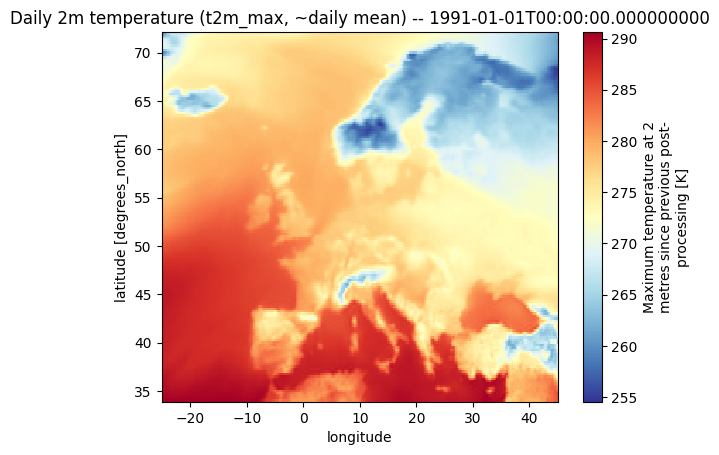

In [14]:
# ERA5_BBOX (the C3S ESOTC domain, 25W-45E, 34N-72N) is defined with EU_BBOX in Section 3.
# Applied to both the daily and the monthly store, right after opening.


def subset_era5(da):
    """Subset a Planette ERA5 array to ERA5_BBOX and 1991-2024, with standard lat/lon names."""
    lat_name = 'latitude' if 'latitude' in da.dims else 'lat'
    lon_name = 'longitude' if 'longitude' in da.dims else 'lon'

    # Re-express longitude as -180..180 if the store uses 0..360, so ERA5_BBOX slices directly
    if float(da[lon_name].max()) > 180:
        da = da.assign_coords(
            **{lon_name: (((da[lon_name] + 180) % 360) - 180)}
        ).sortby(lon_name)

    # Latitude may be ascending or descending -- build the slice to match
    lat_descending = float(da[lat_name][0]) > float(da[lat_name][-1])
    lat_slice = (
        slice(ERA5_BBOX['lat_max'], ERA5_BBOX['lat_min']) if lat_descending
        else slice(ERA5_BBOX['lat_min'], ERA5_BBOX['lat_max'])
    )

    da = da.sel(
        **{
            lat_name: lat_slice,
            lon_name: slice(ERA5_BBOX['lon_min'], ERA5_BBOX['lon_max']),
        },
        time=slice('1991-01-01', '2024-12-31'),
    )

    # Standardize dimension names to latitude/longitude for the rest of the notebook
    return da.rename({lat_name: 'latitude', lon_name: 'longitude'})


europe_t2m_k = subset_era5(t2m_max)
print(f'Europe subset: {europe_t2m_k.sizes}')

if monthly_session is not None:
    europe_monthly_k = subset_era5(t2m_max_monthly)
    print(f'Europe subset, monthly store: {europe_monthly_k.sizes}')

# Quick sanity-check plot of a single timestep
europe_t2m_k.isel(time=0).plot(cmap='RdYlBu_r')
plt.title(f'Daily 2m temperature (t2m_max, ~daily mean) -- {europe_t2m_k.time.values[0]}')
plt.show()


### Convert to Celsius

**What `t2m_max` represents:** the store's `long_name` is ERA5's *hourly* maximum
temperature (`mx2t`), and Planette's daily values average it over all 24 hours, so the
result behaves like daily **mean** temperature, not the daily maximum. The check below
prints Vienna's daily values for July 2024, a record-hot month: true daily maxima there
would mostly be 30–35 °C, while values around 22–27 °C indicate daily means. The variable is
therefore labelled `t2m` (daily-mean 2 m temperature).


In [15]:
daily_t2m_c = europe_t2m_k - 273.15
daily_t2m_c.name = 't2m'
daily_t2m_c.attrs['units'] = 'degC'

# Diagnostic: is t2m_max really the daily maximum?
print(f'{VARIABLE} attrs: {ds[VARIABLE].attrs}')
print(f'Dataset attrs: {ds.attrs}')

# July 2024 was record-hot in Vienna: true daily maxima should mostly be 30-35C;
# values around 22-27C mean these are daily means, not maxima
vienna_jul = (
    daily_t2m_c.sel(latitude=48.2, longitude=16.37, method='nearest')
    .sel(time='2024-07')
    .compute()
)
print('Vienna, July 2024 daily values (C):')
print(vienna_jul.round(1).values)
print(f'July mean: {float(vienna_jul.mean()):.1f}C | July max: {float(vienna_jul.max()):.1f}C')

daily_t2m_c


t2m_max attrs: {'units': 'K', 'long_name': 'Maximum temperature at 2 metres since previous post-processing'}
Dataset attrs: {'GRIB_centre': 'ecmf', 'GRIB_centreDescription': 'European Centre for Medium-Range Weather Forecasts', 'GRIB_subCentre': 0, 'Conventions': 'CF-1.7', 'institution': 'European Centre for Medium-Range Weather Forecasts', 'history': '2025-11-17T07:25 GRIB to CDM+CF via cfgrib-0.9.15.0/ecCodes-2.42.0 with {"source": "tmp57d7qigx/data.grib", "filter_by_keys": {"stream": ["oper"], "stepType": ["max"]}, "encode_cf": ["parameter", "time", "geography", "vertical"]}'}
Vienna, July 2024 daily values (C):
[21.7 20.  18.8 19.1 22.1 25.3 21.5 22.4 26.1 28.5 26.3 26.4 24.3 24.5
 26.8 27.8 24.9 25.1 26.4 24.5 26.1 24.4 24.  22.8 21.8 24.6 27.5 25.5
 23.  22.6 26.2]
July mean: 24.2C | July max: 28.5C


<xarray.DataArray 't2m' (time: 12419, latitude: 153, longitude: 281)> Size: 2GB
dask.array<sub, shape=(12419, 153, 281), dtype=float32, chunksize=(31, 153, 281), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 99kB 1991-01-01 1991-01-02 ... 2024-12-31
  * latitude   (latitude) float32 612B 72.0 71.75 71.5 71.25 ... 34.5 34.25 34.0
  * longitude  (longitude) float32 1kB -25.0 -24.75 -24.5 ... 44.5 44.75 45.0
Attributes:
    units:      degC
    long_name:  Maximum temperature at 2 metres since previous post-processing

### Monthly store check

Before the monthly store is used, it is checked against the daily store (reading one or two
daily chunks). The check runs only when the grids are computed, not when they are loaded
from cache:

1. **Same grid:** identical latitude/longitude coordinates to the daily store.
2. **Time labelling:** reports whether months are labelled by month start, month end or
   mid-month, and aligns every label to the start of its month (`MS`).
3. **Completeness:** 12 months in every year, 408 months for 1991–2024, no duplicates.
4. **Values:** July 2024 from the monthly store vs the mean of the daily values for July
   2024 at Vienna, Madrid, Moscow and Istanbul, which must agree within 0.05 °C. If the
   store's June or August matches instead, the labels are a month off.

If any check fails, the reason is printed and `USE_MONTHLY_STORE` is set to `False`, so the
grids are built from the daily store.


In [16]:
MONTHLY_TOLERANCE_C = 0.05
VERIFY_POINTS = {
    'Vienna':   (48.2, 16.37),
    'Madrid':   (40.42, -3.70),
    'Moscow':   (55.76, 37.62),
    'Istanbul': (41.01, 28.98),
}

if not USE_MONTHLY_STORE:
    print('Monthly store not in use -- the grids will be built from the daily store.')
elif grids_cache_usable():
    print('Anomaly grids will be loaded from cache -- ERA5 is not read, so the check is skipped.')
else:
    with timed('Monthly store check'):
        problems = []
        monthly_c = europe_monthly_k - 273.15
        monthly_c.name = 't2m'
        monthly_c.attrs['units'] = 'degC'

        # 1. Same grid as the daily store
        if not (np.array_equal(monthly_c.latitude, daily_t2m_c.latitude)
                and np.array_equal(monthly_c.longitude, daily_t2m_c.longitude)):
            problems.append('monthly and daily latitude/longitude grids differ')

        # 2. Time labelling -> align every label to the start of its month ('MS')
        t = pd.DatetimeIndex(monthly_c.time.values)
        if (t.day == 1).all() and (t == t.normalize()).all():
            labelling = 'month start'
        elif t.is_month_end.all():
            labelling = 'month end'
        else:
            labelling = f'other, e.g. mid-month (first label {t[0]})'
        print(f'Monthly store time labels: {labelling} -> aligned to month start')
        monthly_c = monthly_c.assign_coords(time=t.to_period('M').to_timestamp())

        # 3. Completeness: 12 months per year, 408 months for 1991-2024, no duplicates
        aligned = pd.DatetimeIndex(monthly_c.time.values)
        expected = pd.date_range('1991-01-01', '2024-12-01', freq='MS')
        print(f'Months found: {len(aligned)} (expected {len(expected)})')
        if not aligned.equals(expected):
            problems.append(f'expected the {len(expected)} months 1991-01..2024-12, found '
                            f'{len(aligned)} ({aligned.min():%Y-%m}..{aligned.max():%Y-%m}, '
                            f'unique: {aligned.is_unique})')

        # 4. Values: July 2024, monthly store vs the July mean of the daily store
        if aligned.is_unique:
            lat_da = xr.DataArray([p[0] for p in VERIFY_POINTS.values()], dims='point')
            lon_da = xr.DataArray([p[1] for p in VERIFY_POINTS.values()], dims='point')
            daily_jul = (
                daily_t2m_c.sel(latitude=lat_da, longitude=lon_da, method='nearest')
                .sel(time='2024-07').mean('time')
            )
            store_months = (
                monthly_c.sel(latitude=lat_da, longitude=lon_da, method='nearest')
                .sel(time=slice('2024-06-01', '2024-08-01'))
            )
            daily_jul, store_months = dask.compute(daily_jul, store_months)

            table = pd.DataFrame({'daily-derived Jul 2024': daily_jul.values}, index=list(VERIFY_POINTS))
            for ts in store_months.time.values:
                table[f'store {pd.Timestamp(ts):%b %Y}'] = store_months.sel(time=ts).values
            print(table.round(3).to_string())

            jul = pd.Timestamp('2024-07-01')
            if jul in pd.DatetimeIndex(store_months.time.values):
                diff = np.abs(store_months.sel(time=jul).values - daily_jul.values)
                print(f'Max |store - daily| for July 2024: {diff.max():.3f}C '
                      f'(tolerance {MONTHLY_TOLERANCE_C}C)')
                if not (diff <= MONTHLY_TOLERANCE_C).all():
                    problems.append(f'July 2024 values differ by up to {diff.max():.2f}C')
                    for ts in store_months.time.values:
                        other = np.abs(store_months.sel(time=ts).values - daily_jul.values)
                        if pd.Timestamp(ts) != jul and (other <= MONTHLY_TOLERANCE_C).all():
                            problems.append(f'the store value labelled {pd.Timestamp(ts):%b %Y} '
                                            'matches daily July -- the labels are a month off')
            else:
                problems.append('no July 2024 value in the monthly store')
        else:
            problems.append('duplicate months -- value check not possible')

        if problems:
            USE_MONTHLY_STORE = False
            print('MONTHLY STORE CHECK FAILED -- falling back to the daily store:')
            for p in problems:
                print(f'  - {p}')
        else:
            europe_monthly_c = monthly_c  # verified, labels aligned to month start
            print('Monthly store check PASSED -- the grids will be computed from the monthly store.')


Anomaly grids will be loaded from cache -- ERA5 is not read, so the check is skipped.


### Climatology, anomaly, and annual aggregation

The method follows the WMO-No. 1203 / Copernicus C3S convention: **monthly means** →
1991–2020 **monthly climatology** → **monthly anomalies** → annual anomaly as the mean of
the 12 monthly anomalies, **each month weighted equally**. The baseline and the 2021–2024
recent-period means use the same weighting, so `recent_t2m - baseline_t2m` equals the
anomaly exactly (checked by an assertion).

A monthly (step) climatology suits monthly and annual means; daily-level analyses such as
heatwave counts would need a smoothed day-of-year climatology.

The three grids are cached to `era5_anomaly_grids.nc`; the cell prints whether they were
computed or loaded.


In [17]:
%%time
# Baseline: 1991-2020, the current WMO standard 30-year reference period and the baseline
# Copernicus/WMO use in their European State of the Climate reports (Section 10).

if grids_cache_usable():
    with timed('Anomaly grids (cache load)'):
        cached = xr.load_dataset(GRIDS_CACHE_PATH)
        annual_anomaly = cached['annual_anomaly']
        baseline_mean = cached['baseline_mean']
        recent_t2m_grid = cached['recent_t2m_grid']
        grids_source = f"cache ({GRIDS_CACHE_PATH}; computed from {cached.attrs.get('source')})"
else:
    with timed('Anomaly grids (ERA5 read + compute)'):
        if USE_MONTHLY_STORE:
            grids_source = f'monthly store s3://{BUCKET}/{MONTHLY_PREFIX}'
            monthly = europe_monthly_c  # verified and aligned to month start above

            # Completeness check: 12 months in every year, 408 months for 1991-2024
            nmonths = monthly.time.groupby('time.year').count()
            assert (nmonths == 12).all() and monthly.sizes['time'] == 408, nmonths.values
        else:
            grids_source = f'daily store s3://{BUCKET}/{PREFIX}, resampled to monthly'

            # Completeness check: every year must have all its days, otherwise the monthly
            # means below would silently be built from partial months
            ndays = daily_t2m_c.time.groupby('time.year').count()
            assert ((ndays == 365) | (ndays == 366)).all(), ndays.values

            monthly = daily_t2m_c.resample(time='MS').mean()

        # WMO-No. 1203 / C3S convention: monthly means -> monthly climatology ->
        # monthly anomalies -> annual mean of the 12 months, each month weighted equally
        baseline_monthly = (
            monthly.sel(time=slice('1991-01-01', '2020-12-31'))
            .groupby('time.month')
            .mean('time')
        )

        # Anomaly cube: departure from the climatological normal for that calendar month
        anomaly = monthly.groupby('time.month') - baseline_monthly

        annual_anomaly = anomaly.groupby('time.year').mean('time')   # 12 months, equal weight
        baseline_mean = baseline_monthly.mean('month')

        # Recent period 2021-2024: the years after the baseline, so the anomaly is never
        # measured against itself. Computed like baseline_mean (an equal-weighted mean of
        # monthly means), so the two are directly comparable.
        recent_monthly = (
            monthly.sel(time=slice('2021-01-01', '2024-12-31'))
            .groupby('time.month')
            .mean('time')
        )
        recent_t2m_grid = recent_monthly.mean('month')

        # This is where the computation actually runs -- one dask.compute() over the shared
        # graph, so the data are read once for all three results
        annual_anomaly, baseline_mean, recent_t2m_grid = dask.compute(
            annual_anomaly, baseline_mean, recent_t2m_grid
        )

    # Cache the three grids (a few MB) so later runs skip ERA5 entirely. 'year' is cast to
    # int32 so any installed netCDF engine (netCDF4, h5netcdf or scipy) can write the file.
    grids = xr.Dataset({
        'annual_anomaly': annual_anomaly,
        'baseline_mean': baseline_mean,
        'recent_t2m_grid': recent_t2m_grid,
    })
    grids = grids.assign_coords(year=grids['year'].astype('int32'))
    grids.attrs = {**grid_cache_params(), 'source': grids_source}
    try:
        grids.to_netcdf(GRIDS_CACHE_PATH)
        print(f'Cached anomaly grids to {GRIDS_CACHE_PATH}')
    except Exception as e:
        print(f'WARNING: could not write the grid cache ({type(e).__name__}: {e}); '
              'the analysis continues, but the next run will recompute.')

print(f'Anomaly grids from: {grids_source}')

# Consistency check: with equal monthly weighting throughout, recent minus baseline must
# equal the 2021-2024 mean of the annual anomalies
xr.testing.assert_allclose(
    recent_t2m_grid - baseline_mean,
    annual_anomaly.sel(year=slice(2021, 2024)).mean('year'),
    atol=1e-4,
)

print('Computation complete.')
print(f'Annual anomaly grid: {dict(annual_anomaly.sizes)}')


[timing] Anomaly grids (cache load): 1.0s
Anomaly grids from: cache (/content/drive/MyDrive/python-remote-sensing-europe-climate/era5_anomaly_grids.nc; computed from monthly store s3://planette-era5/era5/t2m_max/month/0p25latx0p25lon/era5_t2m_max_month_0p25latx0p25lon.zarr)
Computation complete.
Annual anomaly grid: {'year': 34, 'latitude': 153, 'longitude': 281}
CPU times: user 71.4 ms, sys: 3.47 ms, total: 74.9 ms
Wall time: 1.09 s


### Extract values at every city — one vectorized selection, no loop

Passing `city`-dimensioned arrays of latitudes and longitudes to `.sel()` returns one value
per city in a single call.


In [18]:
city_lat_da = xr.DataArray(cities['latitude'].values, dims='city')
city_lon_da = xr.DataArray(cities['longitude'].values, dims='city')

recent_anomaly_grid = annual_anomaly.sel(year=slice(2021, 2024)).mean('year')

city_annual = annual_anomaly.sel(latitude=city_lat_da, longitude=city_lon_da, method='nearest')

cities_climate = cities.copy()
cities_climate['anomaly'] = recent_anomaly_grid.sel(
    latitude=city_lat_da, longitude=city_lon_da, method='nearest'
).values
cities_climate['baseline_t2m'] = baseline_mean.sel(
    latitude=city_lat_da, longitude=city_lon_da, method='nearest'
).values
cities_climate['recent_t2m'] = recent_t2m_grid.sel(
    latitude=city_lat_da, longitude=city_lon_da, method='nearest'
).values
cities_climate['anomaly_2024'] = city_annual.sel(year=2024).values
cities_climate['anomaly_2023'] = city_annual.sel(year=2023).values
cities_climate['anomaly_2022'] = city_annual.sel(year=2022).values

print(f'Cities with anomaly data: {len(cities_climate)}')
print(f'Anomaly range: {cities_climate["anomaly"].min():+.1f}C to '
      f'{cities_climate["anomaly"].max():+.1f}C')
print(f'Mean anomaly across all cities: {cities_climate["anomaly"].mean():+.1f}C')

cities_climate[['city_name', 'country_code', 'population', 'anomaly',
                'baseline_t2m', 'recent_t2m']] \
    .sort_values('anomaly', ascending=False) \
    .head(10) \
    .round(1)

Cities with anomaly data: 113
Anomaly range: +0.3C to +1.6C
Mean anomaly across all cities: +1.0C


,city_name,country_code,population,anomaly,baseline_t2m,recent_t2m
49,Bucharest,RO,1883425,1.6,11.9,13.500000
85,Kahramanmaraş,TR,1112634,1.5,14.7,16.200001
77,Gaziantep,TR,2164134,1.3,16.5,17.799999
52,Vienna,AT,2042036,1.3,10.6,11.900000
78,Şanlıurfa,TR,2143020,1.3,17.4,18.700001
23,Turin,IT,861341,1.3,12.6,13.900000
84,Adıyaman,TR,632459,1.3,15.3,16.600000
103,Kharkiv,UA,1447652,1.3,8.6,9.900000
12,Barcelona,ES,1713247,1.3,15.4,16.600000
107,Donetsk,UA,929063,1.3,9.4,10.700000


Save the per-city anomaly table as CSV.


In [19]:
anomaly_filepath = os.path.join(output_folder, 'eu_cities_climate.csv')
cities_climate.drop(columns='geometry').to_csv(anomaly_filepath, index=False)
print(f'Wrote {anomaly_filepath}')

Wrote /content/drive/MyDrive/python-remote-sensing-europe-climate/eu_cities_climate.csv


---
## 6. Analysis: Anomaly Distribution and Population Exposure

Population exposure is a direct attribute sum, not a spatial raster operation:

```
exposed_population = SUM(population) for cities where anomaly >= threshold
```

/tmp/ipykernel_811/7188229.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


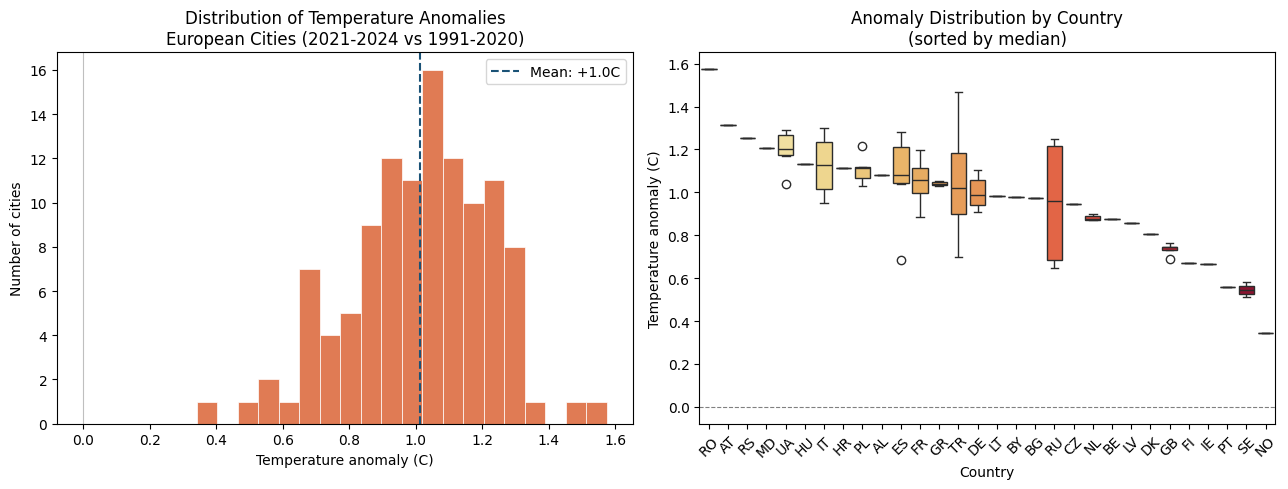

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(cities_climate['anomaly'], bins=20,
             color='#e07b54', edgecolor='white', linewidth=0.5)
axes[0].axvline(cities_climate['anomaly'].mean(), color='#1a5276',
                linestyle='--', linewidth=1.5,
                label=f'Mean: {cities_climate["anomaly"].mean():+.1f}C')
axes[0].axvline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)
axes[0].set_title('Distribution of Temperature Anomalies\nEuropean Cities (2021-2024 vs 1991-2020)')
axes[0].set_xlabel('Temperature anomaly (C)')
axes[0].set_ylabel('Number of cities')
axes[0].legend()

country_order = (
    cities_climate.groupby('country_code')['anomaly']
    .median().sort_values(ascending=False).index.tolist()
)
sns.boxplot(
    data=cities_climate,
    x='country_code', y='anomaly',
    order=country_order,
    palette='YlOrRd',
    ax=axes[1]
)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_title('Anomaly Distribution by Country\n(sorted by median)')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Temperature anomaly (C)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [21]:
print('=== POPULATION EXPOSURE SUMMARY ===')
print(f'Total cities analysed: {len(cities_climate)}')
print(f'Total population covered: {cities_climate["population"].sum()/1e6:.0f}M')
print()

for threshold in [0.5, 1.0, 1.5, 2.0, 2.5]:
    exposed = cities_climate[cities_climate['anomaly'] >= threshold]
    pop_exposed = exposed['population'].sum() / 1e6
    n_cities = len(exposed)
    print(f'Anomaly >= +{threshold:.1f}C:  '
          f'{n_cities:>3} cities  |  '
          f'{pop_exposed:>6.1f}M people exposed')

=== POPULATION EXPOSURE SUMMARY ===
Total cities analysed: 113
Total population covered: 172M

Anomaly >= +0.5C:  112 cities  |   170.9M people exposed
Anomaly >= +1.0C:   62 cities  |    78.7M people exposed
Anomaly >= +1.5C:    1 cities  |     1.9M people exposed
Anomaly >= +2.0C:    0 cities  |     0.0M people exposed
Anomaly >= +2.5C:    0 cities  |     0.0M people exposed


In [22]:
country_summary = cities_climate.groupby('country_code').agg(
    city_count=('city_name', 'count'),
    mean_anomaly=('anomaly', 'mean'),
    max_anomaly=('anomaly', 'max'),
    total_population=('population', 'sum')
).round(3).reset_index()

country_summary['total_population_M'] = (
    country_summary['total_population'] / 1e6
).round(1)

country_summary = country_summary.sort_values('mean_anomaly', ascending=False)
print('Country-level anomaly summary:')
country_summary[['country_code', 'city_count', 'mean_anomaly',
                  'max_anomaly', 'total_population_M']].round(1)

Country-level anomaly summary:


,country_code,city_count,mean_anomaly,max_anomaly,total_population_M
24,RO,1,1.6,1.6,1.9
1,AT,1,1.3,1.3,2.0
25,RS,1,1.3,1.3,1.2
19,MD,1,1.2,1.2,0.8
29,UA,9,1.2,1.3,10.1
14,HU,1,1.1,1.1,1.7
16,IT,6,1.1,1.3,7.2
13,HR,1,1.1,1.1,0.7
22,PL,5,1.1,1.2,4.7
0,AL,1,1.1,1.1,0.6


---
## 7. Within-Country Anomaly Percentile Ranking

DuckDB's `PERCENT_RANK()` window function ranks each city's anomaly against the other major
cities in the same country, independent of the country's overall climate. A city at the
90th percentile has a larger anomaly than 90% of its country's other major cities.

**Caveat:** a country with only 1–2 cities can only score 0% or 100%, so the `high_anomaly`
filter below is restricted to countries with at least 3 cities.


In [23]:
con.register('cities_climate_df', cities_climate.drop(columns='geometry'))
con.sql('CREATE OR REPLACE TABLE eu_city_climate AS SELECT * FROM cities_climate_df')

city_ranked = con.sql("""
    SELECT
        *,
        PERCENT_RANK() OVER (
            PARTITION BY country_code
            ORDER BY anomaly
        ) AS anomaly_percentile
    FROM eu_city_climate
""").df()

print('Cities ranked by within-country anomaly percentile (top 10):')
city_ranked[['city_name', 'country_code', 'anomaly', 'anomaly_percentile', 'population']] \
    .sort_values('anomaly', ascending=False) \
    .head(10) \
    .round({'anomaly': 1})

Cities ranked by within-country anomaly percentile (top 10):


,city_name,country_code,anomaly,anomaly_percentile,population
48,Bucharest,RO,1.6,0.000000,1883425
90,Kahramanmaraş,TR,1.5,1.000000,1112634
89,Gaziantep,TR,1.3,0.965517,2164134
31,Vienna,AT,1.3,0.000000,2042036
88,Şanlıurfa,TR,1.3,0.931034,2143020
96,Turin,IT,1.3,1.000000,861341
87,Adıyaman,TR,1.3,0.896552,632459
23,Kharkiv,UA,1.3,1.000000,1447652
112,Barcelona,ES,1.3,1.000000,1713247
22,Donetsk,UA,1.3,0.875000,929063


In [24]:
# Percentiles need enough cities to rank against: require >= 3 cities per country.
MIN_CITIES_PER_COUNTRY = 3
city_ranked['country_city_count'] = city_ranked.groupby('country_code')['city_name'].transform('count')

small_sample_countries = sorted(
    city_ranked.loc[city_ranked['country_city_count'] < MIN_CITIES_PER_COUNTRY, 'country_code'].unique()
)
print(f'Countries with fewer than {MIN_CITIES_PER_COUNTRY} cities in the sample '
      f'(percentile not meaningful, excluded below): {small_sample_countries}')

# High anomaly cities: top 20% nationally AND anomaly > +1C, restricted to countries
# where the percentile is actually meaningful
high_anomaly = city_ranked[
    (city_ranked['anomaly_percentile'] >= 0.8) &
    (city_ranked['anomaly'] >= 1.0) &
    (city_ranked['country_city_count'] >= MIN_CITIES_PER_COUNTRY)
].copy()

print(f'High anomaly cities (top 20% nationally, anomaly >= +1C): {len(high_anomaly)}')
print(f'Total population exposed: {high_anomaly["population"].sum()/1e6:.1f}M')
high_anomaly[['city_name', 'country_code', 'anomaly', 'anomaly_percentile', 'population']] \
    .sort_values('anomaly', ascending=False) \
    .round({'anomaly': 1})

Countries with fewer than 3 cities in the sample (percentile not meaningful, excluded below): ['AL', 'AT', 'BE', 'BG', 'BY', 'CZ', 'DK', 'FI', 'GR', 'HR', 'HU', 'IE', 'LT', 'LV', 'MD', 'NO', 'PT', 'RO', 'RS', 'SE']
High anomaly cities (top 20% nationally, anomaly >= +1C): 19
Total population exposed: 27.1M


,city_name,country_code,anomaly,anomaly_percentile,population
90,Kahramanmaraş,TR,1.5,1.000000,1112634
89,Gaziantep,TR,1.3,0.965517,2164134
88,Şanlıurfa,TR,1.3,0.931034,2143020
96,Turin,IT,1.3,1.000000,861341
87,Adıyaman,TR,1.3,0.896552,632459
23,Kharkiv,UA,1.3,1.000000,1447652
112,Barcelona,ES,1.3,1.000000,1713247
22,Donetsk,UA,1.3,0.875000,929063
86,Adana,TR,1.3,0.862069,2258718
95,Rome,IT,1.3,0.800000,2802048


---
## 8. Final Maps: Temperature Anomaly and Population Exposure

**Per-city point map:**
- **Circle colour** -- anomaly magnitude (blue = near-normal, orange/red = above baseline)
- **Circle size** -- log(population)
- **Red border** -- top 20% national anomaly percentile
- **Popup** -- city name, country, population, anomaly, baseline temperature, percentile

With 100+ cities this gets visually busy up close, so it's followed by a **country-level
choropleth** (Section 8b) that aggregates the same anomaly values to answer the "where" at
a glance.

In [25]:
def anomaly_to_hex(val, vmin=-0.5, vmax=3.5):
    """Map anomaly value to a blue -> orange -> red hex colour."""
    t = max(0, min(1, (val - vmin) / (vmax - vmin)))
    if t < 0.5:
        r = int(50 + t * 2 * (240 - 50))
        g = int(130 + t * 2 * (140 - 130))
        b = int(200 - t * 2 * (200 - 30))
    else:
        t2 = (t - 0.5) * 2
        r = int(240 + t2 * (200 - 240))
        g = int(140 - t2 * (140 - 30))
        b = int(30)
    return f'#{r:02x}{g:02x}{b:02x}'

# If these tiles don't load, use tiles='OpenStreetMap' in folium.Map(...) instead
m2 = folium.Map(location=[50, 15], zoom_start=4, tiles=None)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Esri, HERE, Garmin, &copy; OpenStreetMap contributors',
    name='Esri Dark Gray',
).add_to(m2)

for _, row in city_ranked.iterrows():
    col = anomaly_to_hex(row['anomaly'])
    radius = max(5, min(22, np.log10(row['population'] + 1) * 4))
    high = row['anomaly_percentile'] >= 0.8 and row['anomaly'] >= 1.0

    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=radius,
        color='#ff4444' if high else col,
        fill=True,
        fill_color=col,
        fill_opacity=0.85,
        weight=2 if high else 0.5,
        popup=folium.Popup(
            f'<b>{row["city_name"]}</b> ({row["country_code"]})<br>'
            f'Population: {int(row["population"]):,}<br>'
            f'Anomaly (2021-2024 vs 1991-2020): '
            f'<b>{row["anomaly"]:+.1f}C</b><br>'
            f'Baseline T2m (daily mean): {row["baseline_t2m"]:.1f}C<br>'
            f'National anomaly percentile: {row["anomaly_percentile"]:.0%}'
            f'{"<br><b style=color:#ff6666>Top 20% national anomaly</b>" if high else ""}',
            max_width=240
        ),
        tooltip=(
            f'{row["city_name"]}: '
            f'{row["anomaly"]:+.1f}C anomaly | '
            f'pop {int(row["population"])/1e6:.1f}M'
        )
    ).add_to(m2)

print('Colour: blue = near-normal | orange/red = above baseline')
print('Size = log(population) | Red border = top 20% national anomaly percentile')
m2

Colour: blue = near-normal | orange/red = above baseline
Size = log(population) | Red border = top 20% national anomaly percentile


---
## 8b. Choropleth: Mean Anomaly by Country

The country-level choropleth shows which countries, as a whole, run warmest relative to
their 1991–2020 baseline. It joins `country_summary` (Section 6) to the Overture
`division_area` country polygons cached in Section 3. The polygons are simplified by
`SIMPLIFY_DEG` (0.02°, about 2 km, invisible at this zoom) and embedded once, with the hover
tooltip on the same layer, which keeps the saved notebook small.


In [26]:
# Country polygons from the division_area result cached in Section 3, matched by the
# country codes in the city data. That query's bbox test intersects the ERA5 domain, so
# countries reaching outside the box (Norway, Turkey, Russia, France, ...) are included.
country_codes = sorted(country_summary['country_code'].unique().tolist())

with timed('Section 8b choropleth'):
    countries_gdf = (
        division_areas.loc[
            (division_areas['subtype'] == 'country') & division_areas['country'].isin(country_codes),
            ['id', 'name', 'country', 'geometry'],
        ]
        .rename(columns={'name': 'country_name', 'country': 'country_code'})
        .copy()
    )

    # Reproject to a projected CRS for accurate area calculation
    countries_gdf_proj = countries_gdf.to_crs('EPSG:3035') # ETRS89-extended / LAEA Europe

    # Keep the most complete polygon per country code (division_area can carry a
    # handful of small variants per country -- dependencies, disputed areas, etc.)
    countries_gdf['area'] = countries_gdf_proj.geometry.area
    countries_gdf = (
        countries_gdf.sort_values('area', ascending=False)
        .drop_duplicates(subset='country_code')
        .reset_index(drop=True)
    )

    print(f'Countries with city data: {len(country_codes)}')
    print(f'Country polygons matched: {len(countries_gdf)}')
    missing = sorted(set(country_codes) - set(countries_gdf['country_code']))
    print(f'Still unmatched (no polygon found for this code at all): {missing}')

    # One GeoJSON for both the fill and the tooltip: simplified geometries (~2 km tolerance,
    # invisible at Europe zoom) with the tooltip fields merged into the feature properties
    choro_gdf = countries_gdf[['country_code', 'country_name', 'geometry']].merge(
        country_summary[['country_code', 'mean_anomaly', 'city_count', 'total_population_M']],
        on='country_code', how='left',
    )
    choro_gdf['geometry'] = choro_gdf.geometry.simplify(SIMPLIFY_DEG, preserve_topology=True)

    # If these tiles don't load, use tiles='OpenStreetMap' in folium.Map(...) instead
    m3 = folium.Map(location=[50, 15], zoom_start=4, tiles=None)
    folium.TileLayer(
        tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
        attr='Tiles &copy; Esri &mdash; Esri, HERE, Garmin, &copy; OpenStreetMap contributors',
        name='Esri Light Gray',
    ).add_to(m3)

    choropleth = folium.Choropleth(
        geo_data=choro_gdf.to_json(),
        data=country_summary,
        columns=['country_code', 'mean_anomaly'],
        key_on='feature.properties.country_code',
        fill_color='YlOrRd',
        fill_opacity=0.8,
        line_opacity=0.4,
        line_color='white',
        legend_name='Mean city anomaly by country (C, 2021-2024 vs 1991-2020)',
        nan_fill_color='#d9d9d9',
    ).add_to(m3)

    # Tooltip on the choropleth's own GeoJSON layer, so the polygons are embedded only once
    choropleth.geojson.add_child(folium.GeoJsonTooltip(
        fields=['country_name', 'mean_anomaly', 'city_count', 'total_population_M'],
        aliases=['Country:', 'Mean anomaly (C):', 'Cities analysed:', 'Population (M):'],
        localize=True,
    ))

m3


Countries with city data: 30
Country polygons matched: 30
Still unmatched (no polygon found for this code at all): []
[timing] Section 8b choropleth: 1.9s


---
## 9. Population vs Anomaly: Who is Most Exposed?

Which cities combine high anomaly magnitude with large populations — where the most
people are experiencing climate change most intensely.

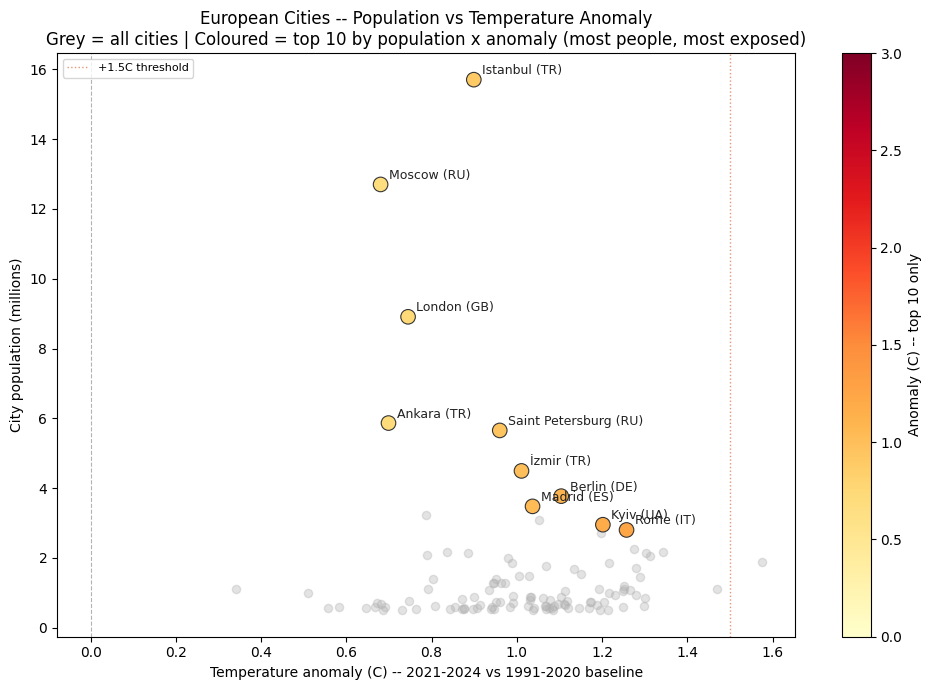

Top 10 most-exposed cities (population x anomaly):


,city_name,country_code,anomaly,population,exposure_score
69,Istanbul,TR,0.9,15701602,1.411680e+07
99,Moscow,RU,0.7,12700000,8.640757e+06
39,London,GB,0.7,8908083,6.635091e+06
102,Saint Petersburg,RU,1.0,5652922,5.426442e+06
75,İzmir,TR,1.0,4493242,4.542307e+06
13,Berlin,DE,1.1,3769962,4.162585e+06
61,Ankara,TR,0.7,5864049,4.098594e+06
108,Madrid,ES,1.0,3477497,3.605604e+06
19,Kyiv,UA,1.2,2952301,3.548235e+06
95,Rome,IT,1.3,2802048,3.523296e+06


In [27]:
# Exposure score: population-weighted anomaly -- who combines a big
# temperature departure with a lot of people experiencing it
city_ranked['exposure_score'] = city_ranked['population'] * city_ranked['anomaly'].clip(lower=0)
top10 = city_ranked.sort_values('exposure_score', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 7))

# Full picture, muted, no legend clutter
ax.scatter(
    city_ranked['anomaly'], city_ranked['population'] / 1e6,
    s=35, color='#b0b0b0', alpha=0.35, zorder=1, label='_nolegend_'
)

# Top 10 most-exposed cities, highlighted and labelled
sc = ax.scatter(
    top10['anomaly'], top10['population'] / 1e6,
    s=110, c=top10['anomaly'], cmap='YlOrRd', vmin=0, vmax=3,
    edgecolor='#333333', linewidth=0.8, zorder=3
)
for _, row in top10.iterrows():
    ax.annotate(
        f"{row['city_name']} ({row['country_code']})",
        xy=(row['anomaly'], row['population'] / 1e6),
        xytext=(6, 4), textcoords='offset points',
        fontsize=9, color='#222222', zorder=4
    )

ax.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
ax.axvline(1.5, color='#e07b54', linestyle=':', linewidth=1, alpha=0.8,
           label='+1.5C threshold')
ax.set_xlabel('Temperature anomaly (C) -- 2021-2024 vs 1991-2020 baseline')
ax.set_ylabel('City population (millions)')
ax.set_title(
    'European Cities -- Population vs Temperature Anomaly\n'
    'Grey = all cities | Coloured = top 10 by population x anomaly (most people, most exposed)'
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Anomaly (C) -- top 10 only')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

print('Top 10 most-exposed cities (population x anomaly):')
top10[['city_name', 'country_code', 'anomaly', 'population', 'exposure_score']] \
    .round({'anomaly': 1})

---
## 10. Validation Against Published Climate Reports

Three checks against independent, published figures:

1. **Magnitude.** The 2024 anomaly grid (`annual_anomaly.sel(year=2024)`),
   cos(latitude)-weighted over land cells only, is compared with published 2024 land-area
   anomalies for Europe and Turkey. A check passes within ±0.3 °C. The benchmarks are for
   mean temperature, which matches `t2m` (Section 5). The mean of the city anomalies for
   2021–2024 is shown as a separate bar for context and is not part of the comparison.
2. **Spatial pattern.** The 2024 land anomaly is mapped, and area-weighted land means are
   compared for a fixed eastern and western box; ESOTC 2024 reports a strong east-west
   contrast, with the east warmer.
3. **Absolute temperatures (sanity check).** City baselines are compared with official WMO
   1991–2020 station normals for both daily maximum and daily mean temperature.

**Sources** (benchmark values transcribed):
- Copernicus/WMO, *European State of the Climate 2024* (ESOTC): Europe 2024 anomaly
  +1.47 °C vs 1991–2020. https://climate.copernicus.eu/esotc/2024
- Turkish State Meteorological Service, *State of the Climate in Turkey in 2024*: +1.7 °C vs
  1991–2020 (15.6 °C vs 13.9 °C).
  https://www.mgm.gov.tr/eng/Yearly-Climate/State_of_the_Climate_in_Turkey_in_2024.pdf
- City normals (sanity check): WMO Climate Normals for 1991–2020, station data sheets
  archived by NOAA NCEI (accession 0253808): annual mean daily maximum and annual mean
  temperature. https://www.ncei.noaa.gov/data/oceans/archive/arc0216/0253808/


Land cells: full resolution 20,064 | simplified 20,048 | cells that differ 112 (0.56%)
Land mask used: simplified
[timing] Section 10 land mask: 5.1s


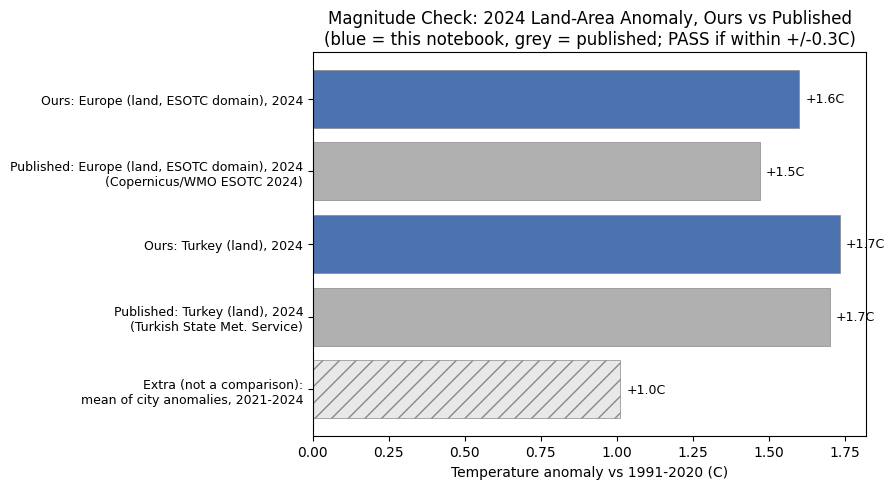

Europe (land, ESOTC domain)    ours +1.6C | published +1.47C | diff +0.1C -> PASS
Turkey (land)                  ours +1.7C | published +1.70C | diff +0.0C -> PASS


In [28]:
import shapely

# --- Land mask on the ERA5 grid ------------------------------------------------------
# Country polygons from the division_area result queried once (and cached) in Section 3. That
# query's bbox test *intersects* the ERA5 domain (not a containment test), so countries
# reaching outside the box (Russia, Turkey, Norway, ...) are kept. If this release flags land
# vs maritime parts, keep only land so territorial seas don't count as land.
land_rows = division_areas['subtype'] == 'country'
if 'is_land' in division_areas.columns:
    land_rows &= division_areas['is_land'].fillna(False).astype(bool)
elif 'class' in division_areas.columns:
    land_rows &= division_areas['class'] == 'land'
land_gdf = (
    division_areas.loc[land_rows, ['country', 'geometry']]
    .rename(columns={'country': 'country_code'})
    .reset_index(drop=True)
)

lon2d, lat2d = np.meshgrid(annual_anomaly['longitude'].values, annual_anomaly['latitude'].values)


def polygon_mask(geoms):
    """Boolean (latitude, longitude) mask of grid-cell centres inside any of the polygons."""
    inside = np.zeros(lon2d.shape, dtype=bool)
    for geom in geoms:
        inside |= shapely.contains_xy(geom, lon2d, lat2d)
    return xr.DataArray(
        inside, dims=('latitude', 'longitude'),
        coords={'latitude': annual_anomaly['latitude'], 'longitude': annual_anomaly['longitude']},
    )


# Use the same simplified geometries as the choropleth only if that changes no more than 1% of
# land cells compared with full resolution; otherwise keep full resolution
with timed('Section 10 land mask'):
    land_mask_full = polygon_mask(land_gdf.geometry)
    land_geoms_simple = land_gdf.geometry.simplify(SIMPLIFY_DEG, preserve_topology=True)
    land_mask_simple = polygon_mask(land_geoms_simple)

    n_full, n_simple = int(land_mask_full.sum()), int(land_mask_simple.sum())
    n_changed = int((land_mask_full != land_mask_simple).sum())
    print(f'Land cells: full resolution {n_full:,} | simplified {n_simple:,} | '
          f'cells that differ {n_changed:,} ({n_changed / n_full:.2%})')
    if n_changed / n_full <= 0.01:
        land_mask, land_geoms, land_mask_resolution = land_mask_simple, land_geoms_simple, 'simplified'
    else:
        land_mask, land_geoms, land_mask_resolution = land_mask_full, land_gdf.geometry, 'full resolution'
    print(f'Land mask used: {land_mask_resolution}')
    tr_mask = polygon_mask(land_geoms[land_gdf['country_code'] == 'TR'])

# Area weights: a regular lat/lon grid cell's area scales with cos(latitude)
area_weights = np.cos(np.deg2rad(annual_anomaly['latitude']))


def land_mean(da, mask):
    """cos(latitude)-weighted mean of da over the masked grid cells."""
    return float(da.where(mask).weighted(area_weights).mean(('latitude', 'longitude')))


# --- Magnitude check: 2024, land only, area-weighted, vs published 2024 figures ----------
# Domain: the ERA5 grid uses the C3S ESOTC European domain (25W-45E, 34N-72N, ERA5_BBOX),
# so the Europe figure covers all land in that box. Note the Overture polygons decide what
# counts as land; C3S uses the ERA5 land-sea mask, so expect small differences.
TOLERANCE_C = 0.3
year_2024 = annual_anomaly.sel(year=2024)

comparisons = pd.DataFrame([
    # Copernicus/WMO European State of the Climate 2024: Europe 2024 = +1.47C vs
    # 1991-2020 (ERA5 surface air temperature, mean temperature, land).
    # Source: https://climate.copernicus.eu/esotc/2024
    {'region': 'Europe (land, ESOTC domain)', 'source': 'Copernicus/WMO ESOTC 2024',
     'ours': land_mean(year_2024, land_mask), 'published': 1.47},
    # Turkish State Meteorological Service: 2024 mean = 15.6C, +1.7C vs the 1991-2020
    # mean of 13.9C. Source:
    # https://www.mgm.gov.tr/eng/Yearly-Climate/State_of_the_Climate_in_Turkey_in_2024.pdf
    {'region': 'Turkey (land)', 'source': 'Turkish State Met. Service',
     'ours': land_mean(year_2024, tr_mask), 'published': 1.70},
])
comparisons['difference'] = comparisons['ours'] - comparisons['published']
comparisons['result'] = np.where(comparisons['difference'].abs() <= TOLERANCE_C, 'PASS', 'FAIL')

# Not a comparison -- the unweighted mean of the city anomalies (2021-2024), for context
city_mean_recent = city_ranked['anomaly'].mean()

labels, values, colors = [], [], []
for _, r in comparisons.iterrows():
    labels += [f"Ours: {r['region']}, 2024", f"Published: {r['region']}, 2024\n({r['source']})"]
    values += [r['ours'], r['published']]
    colors += ['#4C72B0', '#B0B0B0']
labels.append('Extra (not a comparison):\nmean of city anomalies, 2021-2024')
values.append(city_mean_recent)
colors.append('#E8E8E8')

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(values))
bars = ax.barh(y_pos, values, color=colors, edgecolor='#888888', linewidth=0.5)
bars[-1].set_hatch('//')
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Temperature anomaly vs 1991-2020 (C)')
ax.set_title(
    'Magnitude Check: 2024 Land-Area Anomaly, Ours vs Published\n'
    f'(blue = this notebook, grey = published; PASS if within +/-{TOLERANCE_C}C)'
)
for y, v in zip(y_pos, values):
    ax.text(v + 0.02, y, f'{v:+.1f}C', va='center', fontsize=9)
plt.tight_layout()
plt.show()

for _, r in comparisons.iterrows():
    print(f"{r['region']:<30} ours {r['ours']:+.1f}C | published {r['published']:+.2f}C | "
          f"diff {r['difference']:+.1f}C -> {r['result']}")


### Spatial pattern check: east vs west, area-weighted


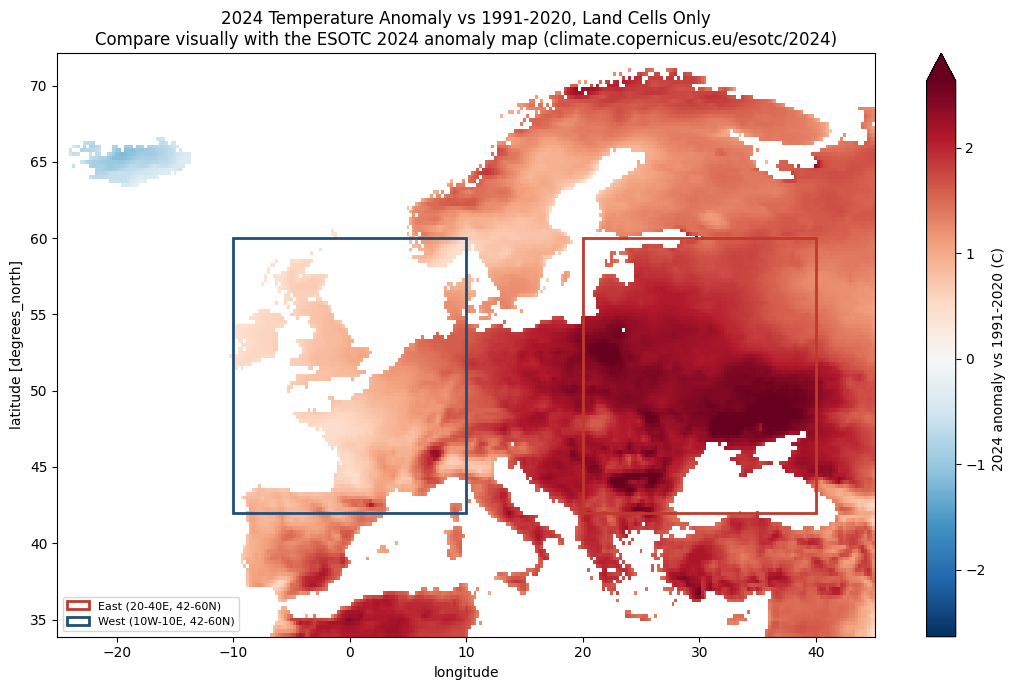

Area-weighted land mean, East (20-40E, 42-60N): +2.1C
Area-weighted land mean, West (10W-10E, 42-60N): +1.0C
East minus west: +1.2C


In [29]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

# Copernicus ESOTC 2024 describes a strong east-west contrast in 2024, with eastern Europe
# warmer. Compare two fixed lon/lat boxes as area-weighted land means of the 2024 grid
# anomaly -- not as averages over however many cities each country happens to have.
REGIONS = {
    'East (20-40E, 42-60N)':  {'lon': (20, 40),  'lat': (42, 60), 'color': '#c0392b'},
    'West (10W-10E, 42-60N)': {'lon': (-10, 10), 'lat': (42, 60), 'color': '#1f4e79'},
}

year_2024_land = year_2024.where(land_mask)
lim = float(np.nanpercentile(np.abs(year_2024_land.values), 99))

fig, ax = plt.subplots(figsize=(11, 7))
year_2024_land.plot(
    ax=ax, cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim),
    cbar_kwargs={'label': '2024 anomaly vs 1991-2020 (C)'},
)

region_means = {}
for name, r in REGIONS.items():
    in_box = (
        (land_mask.latitude >= r['lat'][0]) & (land_mask.latitude <= r['lat'][1]) &
        (land_mask.longitude >= r['lon'][0]) & (land_mask.longitude <= r['lon'][1])
    )
    region_means[name] = land_mean(year_2024, land_mask & in_box)
    ax.add_patch(Rectangle(
        (r['lon'][0], r['lat'][0]), r['lon'][1] - r['lon'][0], r['lat'][1] - r['lat'][0],
        fill=False, edgecolor=r['color'], linewidth=2, label=name,
    ))

ax.legend(loc='lower left', fontsize=8)
ax.set_title(
    '2024 Temperature Anomaly vs 1991-2020, Land Cells Only\n'
    'Compare visually with the ESOTC 2024 anomaly map (climate.copernicus.eu/esotc/2024)'
)
plt.tight_layout()
plt.show()

for name, v in region_means.items():
    print(f'Area-weighted land mean, {name}: {v:+.1f}C')
east, west = region_means.values()
print(f'East minus west: {east - west:+.1f}C')


### Absolute temperature sanity check: variable definition and grid-cell artifacts

As a sanity check, each city's `baseline_t2m` is compared with official WMO 1991–2020 climate
normals for one station per city: annual mean daily maximum and annual mean temperature
(St. Petersburg 26063, Wien Hohe Warte 11035, Berlin-Tempelhof 10384, Roma Ciampino 16239,
Madrid Retiro 8222).

How to read it: an offset of several degrees below the daily-maximum normal at every city,
inland ones included, reflects the variable definition (`t2m` is a daily mean). Against the
mean-temperature normals, differences of up to about 1 °C are expected, because a station
is a single point (often inside a city that runs warmer than its surroundings), while ERA5
averages a ~28 km grid cell that can differ in elevation and include sea.

**Land-fraction caveat:** for coastal cities, the nearest 0.25° grid cell can be mostly sea,
which damps both the absolute temperature and the anomaly.


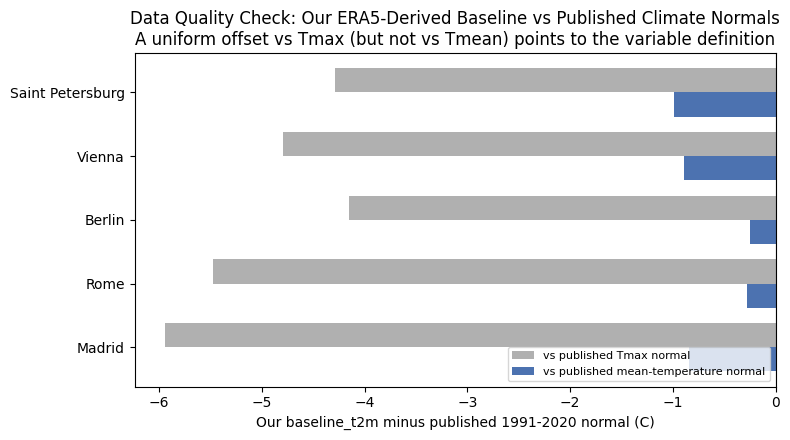

,city_name,baseline_t2m,published_tmax,diff_vs_tmax,published_tmean,diff_vs_tmean
0,Saint Petersburg,5.3,9.6,-4.3,6.3,-1.0
1,Vienna,10.6,15.4,-4.8,11.5,-0.9
2,Berlin,10.1,14.3,-4.2,10.4,-0.3
3,Rome,15.5,21.0,-5.5,15.8,-0.3
4,Madrid,14.7,20.6,-5.9,15.5,-0.8


In [30]:
# Official WMO 1991-2020 climate normals for one station per city, used as a sanity check
# (Source: WMO Climate Normals for 1991-2020, NOAA NCEI accession 0253808,
# https://www.ncei.noaa.gov/data/oceans/archive/arc0216/0253808/):
#  - published_tmax:  annual mean daily MAXIMUM temperature, 1991-2020
#  - published_tmean: annual MEAN temperature, 1991-2020 -- the like-for-like comparison,
#    since t2m_max here behaves like a daily mean (Section 5 diagnostic)
published_normals = pd.DataFrame([
    {'city_name': 'Saint Petersburg', 'published_tmax': 9.6,  'published_tmean': 6.3},   # St. Petersburg, WMO 26063
    {'city_name': 'Vienna',           'published_tmax': 15.4, 'published_tmean': 11.5},  # Wien Hohe Warte, WMO 11035
    {'city_name': 'Berlin',           'published_tmax': 14.3, 'published_tmean': 10.4},  # Berlin-Tempelhof, WMO 10384
    {'city_name': 'Rome',             'published_tmax': 21.0, 'published_tmean': 15.8},  # Roma Ciampino, WMO 16239
    {'city_name': 'Madrid',           'published_tmax': 20.6, 'published_tmean': 15.5},  # Madrid Retiro, WMO 8222
])

check = published_normals.merge(
    city_ranked[['city_name', 'baseline_t2m']], on='city_name', how='left'
)
check['diff_vs_tmax'] = check['baseline_t2m'] - check['published_tmax']
check['diff_vs_tmean'] = check['baseline_t2m'] - check['published_tmean']

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(check))
h = 0.38
ax.barh(y - h / 2, check['diff_vs_tmax'], height=h, color='#B0B0B0',
        label='vs published Tmax normal')
ax.barh(y + h / 2, check['diff_vs_tmean'], height=h, color='#4C72B0',
        label='vs published mean-temperature normal')
ax.set_yticks(y)
ax.set_yticklabels(check['city_name'])
ax.invert_yaxis()
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_xlabel('Our baseline_t2m minus published 1991-2020 normal (C)')
ax.set_title(
    'Data Quality Check: Our ERA5-Derived Baseline vs Published Climate Normals\n'
    'A uniform offset vs Tmax (but not vs Tmean) points to the variable definition'
)
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

check[['city_name', 'baseline_t2m', 'published_tmax', 'diff_vs_tmax',
       'published_tmean', 'diff_vs_tmean']].round(1)


---
## 11. Summary

In [31]:
print('=== EUROPEAN CITIES CLIMATE ANOMALY -- FINAL SUMMARY ===')
print()
print(f'Cities analysed:          {len(city_ranked)}')
print(f'Countries covered:        {city_ranked["country_code"].nunique()}')
print(f'Total population covered: {city_ranked["population"].sum()/1e6:.0f}M')
print('(Population totals reflect the cleaned city list from Section 3: European')
print(' countries only, with overlapping districts and admin units removed.)')
print()
print(f'Mean anomaly (all cities):{city_ranked["anomaly"].mean():+.1f}C')
print(f'Max anomaly:              {city_ranked["anomaly"].max():+.1f}C'
      f' -- {city_ranked.loc[city_ranked["anomaly"].idxmax(), "city_name"]}')
print()

for t in [1.0, 1.5, 2.0]:
    exp = city_ranked[city_ranked['anomaly'] >= t]
    print(f'Cities with anomaly >= +{t:.1f}C:  '
          f'{len(exp):>3} cities | '
          f'{exp["population"].sum()/1e6:.0f}M people')

=== EUROPEAN CITIES CLIMATE ANOMALY -- FINAL SUMMARY ===

Cities analysed:          113
Countries covered:        30
Total population covered: 172M
(Population totals reflect the cleaned city list from Section 3: European
 countries only, with overlapping districts and admin units removed.)

Mean anomaly (all cities):+1.0C
Max anomaly:              +1.6C -- Bucharest

Cities with anomaly >= +1.0C:   62 cities | 79M people
Cities with anomaly >= +1.5C:    1 cities | 2M people
Cities with anomaly >= +2.0C:    0 cities | 0M people


Save the final ranked results table to the `output_folder`.

In [32]:
final_filepath = os.path.join(output_folder, 'eu_cities_climate_ranked.csv')
city_ranked.to_csv(final_filepath, index=False)
print(f'Wrote {final_filepath}')

con.close()

# Timing summary for the heavy steps
print()
print('=== TIMING SUMMARY ===')
for label, secs in timings.items():
    print(f'{label:<45} {secs:8.1f}s')
print(f'{"Total (timed steps)":<45} {sum(timings.values()):8.1f}s')
print(f'Anomaly grids from:      {grids_source}')
print(f'division_area from:      {division_areas_source}')

Wrote /content/drive/MyDrive/python-remote-sensing-europe-climate/eu_cities_climate_ranked.csv

=== TIMING SUMMARY ===
Overture division query (cities)                  77.3s
Overture division_area (one query or cache)        7.1s
ERA5 store connect                                 1.8s
ERA5 open (metadata only)                          2.7s
Anomaly grids (cache load)                         1.0s
Section 8b choropleth                              1.9s
Section 10 land mask                               5.1s
Total (timed steps)                               97.0s
Anomaly grids from:      cache (/content/drive/MyDrive/python-remote-sensing-europe-climate/era5_anomaly_grids.nc; computed from monthly store s3://planette-era5/era5/t2m_max/month/0p25latx0p25lon/era5_t2m_max_month_0p25latx0p25lon.zarr)
division_area from:      cache (/content/drive/MyDrive/python-remote-sensing-europe-climate/overture_division_areas.parquet)


---
## Key Methodological Notes

| Step | Method | Why |
|---|---|---|
| City data | Overture Maps `divisions` theme, `division` points with `subtype='locality'`, S3 GeoParquet via DuckDB | Cloud-native, no download; carries a `population` field |
| Population | Overture's `population` attribute on the `division` feature | No separate population join needed |
| City cleaning | Drop non-European countries (DZ, MA, TN, SY) and admin units that aren't cities (comarcas, urban hromadas); drop localities within 1 km of, or inside the boundary of, a more-populous locality in the same country; in Turkey, keep the most populous locality per province | Avoids counting the same population twice in the exposure totals |
| Temperature | Planette ERA5 `t2m_max` (Zarr + Icechunk via XArray); monthly store, checked against the daily store. It is the 24-h mean of ERA5's hourly maximum, so it behaves like daily **mean** temperature and is labelled `t2m` | Cloud-native, analysis-ready aggregates; whole-grid computation |
| Anomaly computation | Monthly means → 1991-2020 monthly climatology → monthly anomalies → annual mean with each month weighted equally (WMO-No. 1203 / C3S convention); one `dask.compute()` on the default threaded scheduler | Matches WMO/C3S practice; `recent_t2m - baseline_t2m` equals `anomaly` exactly |
| Point extraction | Vectorized `.sel(latitude=..., longitude=..., method='nearest')` with array indexers | All city values in one call |
| Anomaly baseline | 1991-2020 WMO standard normal | The reference period used in Copernicus/WMO reporting |
| Anomaly period | 2021-2024 (post-baseline years only) | Outside the baseline, so the anomaly is not measured against itself |
| Ranking | `PERCENT_RANK()` within country (DuckDB window function), countries with >= 3 cities only | Normalises for national climate; 1-2 city countries can only score 0% or 100% |
| Population exposure | Direct attribute sum | Population is a city-level attribute, no raster needed |
| Limitation: urban heat island | Not modelled -- ERA5's ~0.25 deg (~28 km) grid represents regional climate | City anomalies are a lower bound; the urban surface can run 1-3C warmer |
| Limitation: ERA5 absolute values | ~28 km grid cells; the nearest cell to a coastal city can be mostly sea | Anomalies are more reliable than absolute temperatures |
| Validation | 2024 cos(latitude)-weighted land-only anomaly vs Copernicus ESOTC 2024 (Europe) and TSMS 2024 (Turkey), PASS within ±0.3°C; east-vs-west area-weighted land means; city baselines vs official WMO 1991-2020 station normals (sanity check) | Same year, same area averaging, same type of temperature |
| Performance | Monthly ERA5 store; cached anomaly grids and Overture polygons; simplified choropleth polygons embedded once; spatial-index joins for city cleaning | Short run time and a small saved notebook |

*Data: Overture Maps (ODbL); Planette's ERA5 Archive, based on Copernicus ERA5 via NSF-NCAR
(CC BY 4.0).*
